# 16 · Perfect supplier, track T2: the sealed-test result, to explore

Track T2 asked whether the learned forecaster plus planner from notebook 15 still beats
the textbook rules once the comparison is made fair. Fair here means three things.
The textbook side gets contextual and parametric rules with several times the tuning
budget. A classical seasonal forecaster sits in the same planner. The models are trained
with three seeds. The answer comes from one look at 1,000 sealed test worlds per variant
(seeds 9,000,000–9,000,999).

**The result.** The learned forecaster plus planner beats the best tuned textbook rule in
all three worlds (`base`, `no_fee`, `one_product`). All six primary comparisons are
*practically superior* (JEPA and direct, in each of the three worlds). JEPA and the direct
forecaster are about equal. Seasonal ETS in the same planner only ties the textbook rule.
The full write-up is `experiments/reports/T2-consolidation.md`. This notebook shows where
those numbers come from and lets you poke at them.

**How to use it.** There are three parts:

1. **Arms and pooled results.** What was compared, and the mean score of every arm in every world.
2. **Per-world scores.** Pick a world variant and two arms. You get the paired difference
   with its confidence interval, where the margin went, and how the lead changes with
   holding cost, demand noise and delivery lag.
3. **Re-simulate one world.** Run two or three frozen arms on one *dev* or *tune* world
   and watch daily stock, orders and lost sales.

Cells marked **▶ Try** hold the parameters to change. Edit them and re-run that section
from its parameter cell down. With the defaults the notebook runs top to bottom in a few
minutes on a laptop CPU. Almost all of that time is the planner episodes in part 3.

**Data.** The per-world test scores (`scores.parquet`, one per variant) and the seed-0 JEPA
and direct models are committed under `notebooks/fixtures/t2/`. They are byte-identical to
the artifacts the T2 log records, and the setup cell checks that. Seeds 1 and 2 of the
models are not committed. To re-simulate those arms, point `T2_DATA_ROOT` at a full copy
of the T2 data (a directory with `test/<variant>/scores.parquet` and `models/*.pt`).

**The sealed test is never re-run here.** Part 2 only reads the stored scores. Part 3
simulates dev or tune worlds only and refuses the test split.

In [1]:
import copy
import json
import os
from pathlib import Path

import matplotlib

try:
    from IPython import get_ipython
except ImportError:
    get_ipython = None
_shell = get_ipython() if get_ipython is not None else None
if _shell is not None and getattr(_shell, "run_line_magic", None) is not None:
    _shell.run_line_magic("matplotlib", "inline")
else:
    matplotlib.use("Agg", force=True)
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

while not (Path.cwd() / "pyproject.toml").exists():
    os.chdir("..")

from src.perfect_supplier import analysis
from src.perfect_supplier.bench import report, stats
from src.perfect_supplier.bench.arms import make_policy
from src.perfect_supplier.bench.evaluate import score_matrix
from src.perfect_supplier.bench.log import file_sha256
from src.perfect_supplier.bench.protocol import Protocol, load_frozen
from src.perfect_supplier.sim import simulate
from src.perfect_supplier.world import sample_world

pd.set_option("display.width", 200, "display.max_columns", 40)

DATA_ROOT = Path(os.environ.get("T2_DATA_ROOT", "notebooks/fixtures/t2"))
VARIANTS = ["base", "no_fee", "one_product"]
TRACK = "T2-consolidation"

protocol = Protocol.load()
frozen = [e["config"] for e in load_frozen()["configs"].values()]
t2_log = [json.loads(line) for line in Path(f"experiments/log/{TRACK}.jsonl").read_text().splitlines()]
test_evals = {r["variant"]: r for r in t2_log if r.get("kind") == "test-eval" and r.get("status") == "kept"}


def configs_for(variant: str) -> dict[str, dict]:
    # The frozen config of every T2 arm in one variant, by arm name.
    return {c["name"]: c for c in frozen if c["variant"] == variant}


REFERENCE = {v: report.best_textbook(list(configs_for(v).values())) for v in VARIANTS}

# Provenance: the score files here must be the ones the sealed test eval logged.
for v in VARIANTS:
    path = DATA_ROOT / "test" / v / "scores.parquet"
    logged = next(a["sha256"] for a in test_evals[v]["artifacts"] if a["path"].endswith("scores.parquet"))
    status = "matches the T2 log" if file_sha256(path) == logged else "DOES NOT MATCH the T2 log"
    print(f"{path}: {status}")
print("data root:", DATA_ROOT)
print("reference (best textbook arm by selection score on common tune worlds):", REFERENCE)

notebooks/fixtures/t2/test/base/scores.parquet: matches the T2 log
notebooks/fixtures/t2/test/no_fee/scores.parquet: matches the T2 log
notebooks/fixtures/t2/test/one_product/scores.parquet: matches the T2 log
data root: notebooks/fixtures/t2
reference (best textbook arm by selection score on common tune worlds): {'base': 'ctx2_eoq_joint', 'no_fee': 'ctx2_eoq_joint', 'one_product': 'param_eoq_joint'}


## 1 · The arms

Every arm is a frozen config in `experiments/frozen.json`: 19 arms × 3 variants. Each arm runs
closed-loop on its own copy of each world, with the same demand path. So two arms can be compared
world by world.

| arm | what it is |
| --- | --- |
| `jepa_s0`, `jepa_s1`, `jepa_s2` | planner + JEPA quantile forecaster, three training seeds. **`jepa`** below is their per-world mean (the primary arm) |
| `direct_s0`, `direct_s1`, `direct_s2` | planner + the same network trained without the JEPA latent loss. **`direct`** is their mean |
| `jepa_s0_plain` | seed-0 JEPA with the planner's T2 knobs off (an ablation, outside the comparison families) |
| `seasonal_ets` | the same planner with a tuned seasonal exponential-smoothing forecaster (the classical challenger) |
| `planner_moving_average` | the planner with a 28-day moving-average forecast (no learning) |
| `planner_oracle` | the planner fed the **true** demand distribution: a ceiling, not a real policy |
| `tuned_*`, `param_eoq_joint`, `ctx_eoq_joint`, `ctx2_eoq_joint` | 9 tuned textbook rules. `ctx_` is joint EOQ tuned separately per holding rate, `ctx2_` per holding rate × lag, and `param_` maps the safety factor from the critical ratio |

**The score is margin capture.** It is the share of the margin on every demanded unit that ended
up as equity. 1.0 would mean selling every unit demanded with no order fees and no holding cost.
Differences are shown in **points** (1 pt = 0.01 of margin capture).

**The reference** is the textbook arm with the best *selection score*. That score comes from
1,024 common tune worlds that no tuner used, so the reference is never picked on the worlds it
is compared on. The table lists each arm's kind, its forecaster, whether it is contextual (a
parameter set per world cell), and its tune-time scores.

In [2]:
def arm_table(variant: str) -> pd.DataFrame:
    rows = []
    for name, c in sorted(configs_for(variant).items()):
        rows.append({
            "arm": name,
            "kind": c["kind"],
            "forecaster": c.get("params", {}).get("forecaster", ""),
            "contextual cells": len(c["cells"]) if "cells" in c else "",
            "seed group": c.get("seed_group", ""),
            "model file": Path(c["model"]["path"]).name if "model" in c else "",
            "tune score": c.get("tune_score"),
            "selection score": c.get("select_score"),
        })
    return pd.DataFrame(rows).set_index("arm")


arm_table("base")

,kind,forecaster,contextual cells,seed group,model file,tune score,selection score
arm,,,,,,,
ctx2_eoq_joint,eoq_joint,,18,,,0.956406,0.957135
ctx_eoq_joint,eoq_joint,,3,,,0.956709,0.957033
direct_s0,planner,direct,3,direct,direct-s0.pt,0.958822,NaN
direct_s1,planner,direct,3,direct,direct-s1.pt,NaN,NaN
direct_s2,planner,direct,3,direct,direct-s2.pt,NaN,NaN
jepa_s0,planner,jepa,3,jepa,jepa-s0.pt,0.958995,NaN
jepa_s0_plain,planner,jepa,,,jepa-s0.pt,NaN,NaN
jepa_s1,planner,jepa,3,jepa,jepa-s1.pt,NaN,NaN
jepa_s2,planner,jepa,3,jepa,jepa-s2.pt,NaN,NaN


### Pooled results: every arm's mean score on the sealed test

These are the means the sealed test eval logged in `experiments/log/T2-consolidation.jsonl`, one
column per variant (1,000 worlds each). The second table subtracts each variant's reference, in
points. A positive number beats the best tuned textbook rule.

How to read it:
- The **oracle** row is the ceiling the planner reaches with perfect knowledge of the demand distribution.
- The **seasonal_ets** row is the classical forecaster in the same planner. It sits near zero.
- The **jepa** and **direct** rows sit at about +0.13 to +0.24 pts.
- The `tuned_periodic_*` and engine rules are far below. They do not read the fee or the holding rate.

In [3]:
means = pd.DataFrame({v: test_evals[v]["result"]["means"] for v in VARIANTS})
for group in ("jepa", "direct"):
    means.loc[group] = means.loc[[f"{group}_s{i}" for i in range(3)]].mean()
means = means.sort_values("base", ascending=False)
gap = 100 * (means - pd.Series({v: means.loc[REFERENCE[v], v] for v in VARIANTS}))
display(means.round(5))
display(gap.round(3).rename(columns=lambda v: f"{v} − {REFERENCE[v]}, pts"))

,base,no_fee,one_product
planner_oracle,0.96232,0.98999,0.92680
direct_s2,0.95852,0.98511,0.92481
direct_s1,0.95852,0.98516,0.92483
direct,0.95850,0.98515,0.92476
jepa_s0,0.95846,0.98532,0.92473
direct_s0,0.95845,0.98519,0.92464
jepa_s0_plain,0.95844,0.98308,0.92415
jepa_s1,0.95842,0.98532,0.92471
jepa,0.95842,0.98531,0.92473
jepa_s2,0.95837,0.98529,0.92474


,"base − ctx2_eoq_joint, pts","no_fee − ctx2_eoq_joint, pts","one_product − param_eoq_joint, pts"
planner_oracle,0.624,0.654,0.339
direct_s2,0.244,0.166,0.141
direct_s1,0.243,0.172,0.142
direct,0.241,0.171,0.135
jepa_s0,0.238,0.187,0.132
direct_s0,0.237,0.174,0.124
jepa_s0_plain,0.236,-0.036,0.074
jepa_s1,0.234,0.188,0.130
jepa,0.233,0.186,0.132
jepa_s2,0.228,0.184,0.133


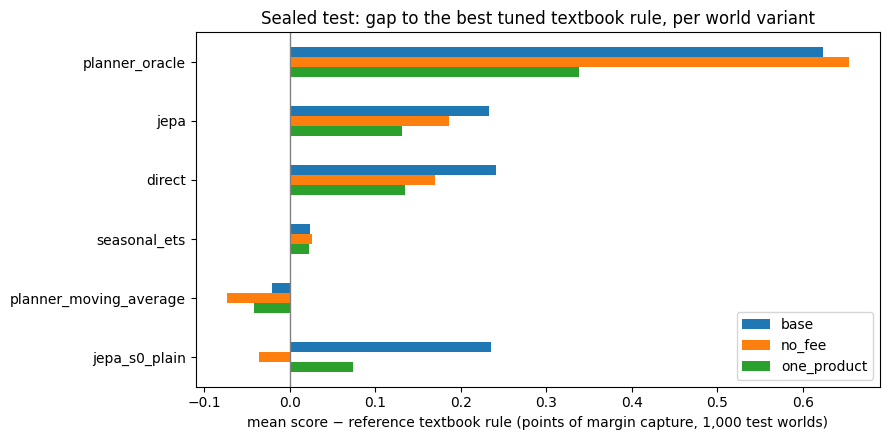

In [4]:
show = ["planner_oracle", "jepa", "direct", "seasonal_ets", "planner_moving_average", "jepa_s0_plain"]
ax = gap.loc[show].plot.barh(figsize=(9, 4.5))
ax.axvline(0, color="grey", lw=1)
ax.invert_yaxis()
ax.set_xlabel("mean score − reference textbook rule (points of margin capture, 1,000 test worlds)")
ax.set_title("Sealed test: gap to the best tuned textbook rule, per world variant")
plt.tight_layout()

### The pre-registered verdict

The labels come from the pooled primary family. That is Holm over all 8 declared comparisons;
T1's two comparisons count as p = 1 because T1 stopped before its test. The labels are logged
by the pooled report:
- *practically superior* means the Holm-adjusted interval is above 0 **and** the estimate is at
  least the SESOI (the smallest effect of interest, 0.1 pts).
- *equivalent* means the 90% interval lies inside ±SESOI.

In [5]:
pooled = [r for r in t2_log if r.get("kind") == "report" and "cells" in r][-1]
verdict = pd.DataFrame(pooled["result"]).T
verdict.index = verdict.index.str.replace(f"{TRACK}/perfect_supplier/", "")
verdict["p_holm"] = verdict["p_holm"].map(lambda p: f"{p:.2g}")
verdict["reference"] = [REFERENCE[name.split(":")[0]] for name in verdict.index]
verdict.rename_axis("variant: arm")

,label,p_holm,reference
variant: arm,,,
base: jepa,practically superior,7.8e-139,ctx2_eoq_joint
base: direct,practically superior,2e-147,ctx2_eoq_joint
no_fee: jepa,practically superior,3.5e-99,ctx2_eoq_joint
no_fee: direct,practically superior,5.3e-91,ctx2_eoq_joint
one_product: jepa,practically superior,1.8e-20,param_eoq_joint
one_product: direct,practically superior,2e-21,param_eoq_joint


## 2 · Per-world scores: pick a variant and two arms

The pooled means hide how the result varies from world to world. Here you pick a world variant,
an arm and a reference, and look at the per-world paired differences `ARM − REF` on the 1,000
test worlds.

**▶ Try:**
- `VARIANT`: one of `base`, `no_fee`, `one_product`.
- `ARM`, `REF`: any arm name from the table above, or the seed groups `jepa` and `direct`.
  `REF = None` uses the variant's reference.

Some pairs worth looking at:
- `jepa` vs `direct`: does the JEPA objective help?
- `jepa` vs `seasonal_ets`: is it just seasonality?
- `planner_oracle` vs `jepa`: how much headroom is left?
- `jepa_s0` vs `jepa_s0_plain`: what the T2 planner knobs add. Try this one in `no_fee`.

In [6]:
VARIANT = "base"
ARM = "jepa"
REF = None  # None: the variant's reference textbook rule

In [7]:
ref = REF or REFERENCE[VARIANT]
scores = pd.read_parquet(DATA_ROOT / "test" / VARIANT / "scores.parquet")
m = score_matrix(scores)  # worlds x arms
for group in ("jepa", "direct"):
    m[group] = m[[f"{group}_s{i}" for i in range(3)]].mean(axis=1)
worlds = scores.drop_duplicates("world_seed").set_index("world_seed").reindex(m.index)

c = stats.compare(m[ARM].to_numpy(), m[ref].to_numpy(), (ARM, ref), protocol.sesoi,
                  level=protocol.stats["level"], n_resamples=protocol.stats["resamples"])
d = m[ARM] - m[ref]
print(f"{VARIANT}: {ARM} − {ref} over {c.n} sealed test worlds")
print(f"  mean paired difference  {100 * c.diff:+.3f} pts   95% BCa [{100 * c.ci[0]:+.3f}, {100 * c.ci[1]:+.3f}]")
print(f"  cost reduction          {100 * c.cost_reduction:+.1f}%      "
      f"[{100 * c.cost_reduction_ci[0]:+.1f}, {100 * c.cost_reduction_ci[1]:+.1f}]  (share of the reference's lost margin removed)")
print(f"  win rate                {c.win_rate:.0%} of worlds")
print(f"  worst 10% of worlds     {100 * c.cvar10:+.3f} pts on average (CVaR10)")
print(f"  paired t p = {c.p_t:.2g}, Wilcoxon p = {c.p_wilcoxon:.2g}, "
      f"TOST p = {c.p_tost:.2g} (small: equivalent within ±{100 * protocol.sesoi:.1f} pts)")

base: jepa − ctx2_eoq_joint over 1000 sealed test worlds
  mean paired difference  +0.233 pts   95% BCa [+0.218, +0.249]
  cost reduction          +5.3%      [+5.0, +5.6]  (share of the reference's lost margin removed)
  win rate                90% of worlds
  worst 10% of worlds     -0.064 pts on average (CVaR10)
  paired t p = 1.1e-139, Wilcoxon p = 7e-140, TOST p = 1 (small: equivalent within ±0.1 pts)


**How to read it.** The interval is a BCa bootstrap over worlds, the protocol's interval. With the
defaults it reproduces the first row of the pooled table (`+0.233 [+0.218, +0.249]` in `base`).
That table's Holm labels widen the interval a little more for multiplicity; this cell shows a
single comparison. Cost reduction puts the same gap in relative terms. The reference loses
`1 − score` of the margin, and this is the share of that loss the arm removes.

The histogram below shows the whole distribution of per-world differences. A mean of +0.2 pts can
hide many small wins and a few large losses. CVaR10 above is the mean of that left tail.

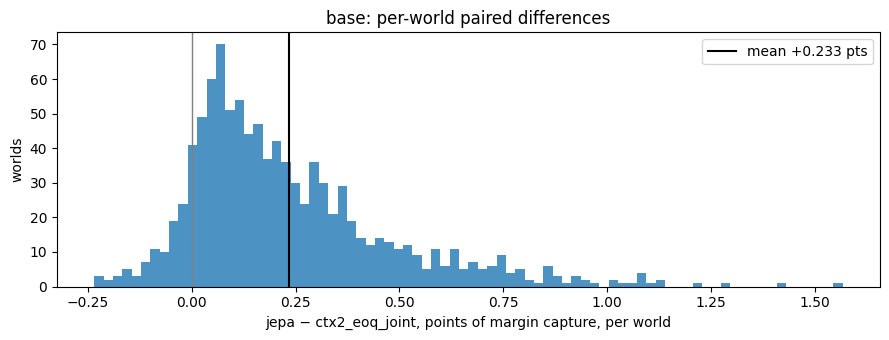

In [8]:
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.hist(100 * d, bins=80, color="tab:blue", alpha=0.8)
ax.axvline(0, color="grey", lw=1)
ax.axvline(100 * c.diff, color="black", lw=1.5, label=f"mean {100 * c.diff:+.3f} pts")
ax.set_xlabel(f"{ARM} − {ref}, points of margin capture, per world")
ax.set_ylabel("worlds")
ax.set_title(f"{VARIANT}: per-world paired differences")
ax.legend()
plt.tight_layout()

### Where the margin went

`report.breakdown` splits the lost margin of each arm into three shares of the total margin:
lost sales, order fees and holding cost. It also gives the number of order days, the fill rate
and the mean stock on hand. Compare the learned arms with the reference. They usually hold less
stock at a similar or higher fill rate.

In [9]:
bd = report.breakdown(scores)
bd.loc[[a for a in bd.index if a in {ARM, ref} or a.startswith(("jepa_s", "direct_s")) or a in
        {"planner_oracle", "seasonal_ets", REFERENCE[VARIANT]}]].round(4)

,score,lost_sales_share,fee_share,holding_share,order_days,fill_rate_demand,mean_on_hand
arm,,,,,,,
planner_oracle,0.9623,0.0029,0.0145,0.0202,47.590,0.9971,72.4761
direct_s2,0.9585,0.0044,0.0152,0.0219,49.649,0.9956,78.0924
direct_s1,0.9585,0.0044,0.0151,0.0219,49.572,0.9956,78.0659
jepa_s0,0.9585,0.0041,0.0152,0.0222,49.961,0.9959,78.9377
direct_s0,0.9585,0.0044,0.0151,0.0220,49.487,0.9956,78.3058
jepa_s0_plain,0.9584,0.0047,0.0151,0.0218,49.288,0.9953,77.5246
jepa_s1,0.9584,0.0041,0.0152,0.0222,49.954,0.9959,79.0346
jepa_s2,0.9584,0.0042,0.0152,0.0222,49.994,0.9958,79.0466
seasonal_ets,0.9563,0.0042,0.0160,0.0235,52.565,0.9958,82.9007


### All arms against the reference, and the strata

The box plot repeats the per-world comparison for every arm against `REF`. Boxes show the middle
half of worlds; outliers are hidden. "JEPA planner" and "direct-forecast planner" are the
seed-group means `jepa` and `direct`. It uses `analysis.plot_paired` from notebook 15. That
module expects the older schema (a `method` column and `split == "eval"`), so `as_legacy` below
renames the columns. The plotting module itself is unchanged.

The **strata** split worlds by the three world parameters the protocol declares:
- `holding_rate`: the daily cost of holding a unit, as a share of its unit cost. The three values
  are 25%, 100% and 365% a year.
- `cv`: the demand noise.
- `delivery_lag`: days from order to arrival.

These splits are exploratory. The report adjusts them with Benjamini–Hochberg. Here each
stratum's mean has its own BCa interval. In T2 the lead grows with the holding rate: a sharper
forecast pays most when stock is expensive.

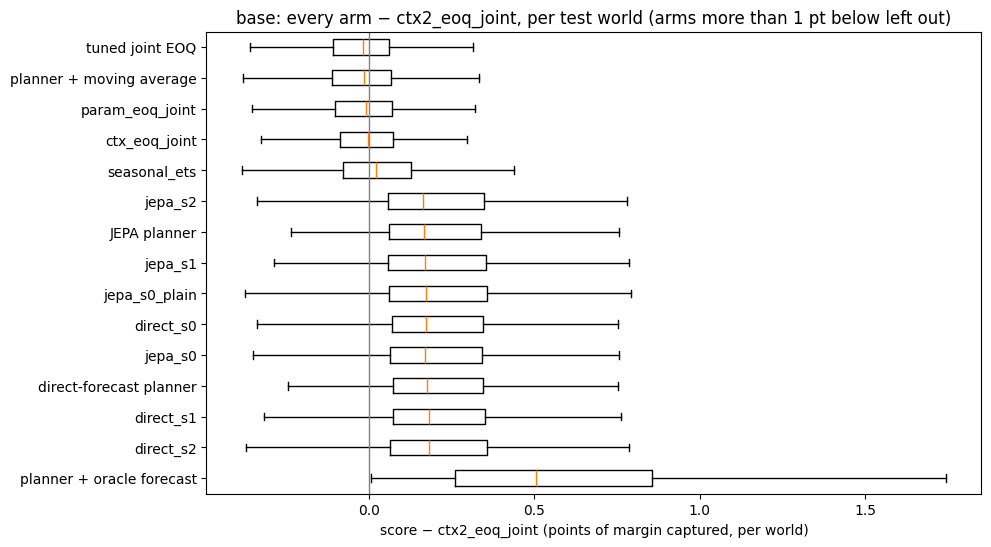

In [10]:
def as_legacy(m: pd.DataFrame, worlds: pd.DataFrame) -> pd.DataFrame:
    # One row per (world, arm) in the schema analysis.plot_* expects.
    long = m.rename_axis(columns="method").stack().rename("score").reset_index()
    return long.assign(split="eval").merge(
        worlds[["holding_rate", "cv", "delivery_lag"]].reset_index(), on="world_seed")


legacy = as_legacy(m, worlds)
order = m.mean().sort_values(ascending=False).index
arms = [a for a in order if a != ref and (m[a] - m[ref]).mean() > -0.01]
fig, ax = plt.subplots(figsize=(10, 6))
analysis.plot_paired(legacy, ref, arms=arms, ax=ax)
ax.set_title(f"{VARIANT}: every arm − {ref}, per test world (arms more than 1 pt below left out)");

In [11]:
rows = []
for key in ("holding_rate", "cv", "delivery_lag"):
    for value, part in d.groupby(worlds[key]):
        lo, hi = stats.bca_ci(part.to_numpy(), n_resamples=2000)
        label = f"{value * 365:.0%}/yr" if key == "holding_rate" else f"{value:g}"
        rows.append({"stratum": key, "value": label, "worlds": len(part),
                     "diff, pts": 100 * part.mean(), "95% low": 100 * lo, "95% high": 100 * hi,
                     "win rate": (part > 0).mean()})
strata = pd.DataFrame(rows).set_index(["stratum", "value"])
print(f"{VARIANT}: {ARM} − {ref} by stratum (exploratory)")
strata.round(3)

base: jepa − ctx2_eoq_joint by stratum (exploratory)


worlds  diff, pts  95% low  95% high  win rate
stratum      value                                                  
holding_rate 25%/yr      329      0.084    0.072     0.095     0.821
             100%/yr     343      0.183    0.168     0.199     0.910
             365%/yr     328      0.437    0.408     0.470     0.970
cv           0.1         331      0.259    0.235     0.284     0.961
             0.3         326      0.188    0.167     0.214     0.874
             0.6         343      0.252    0.221     0.283     0.866
delivery_lag 2           148      0.191    0.161     0.230     0.899
             3           182      0.245    0.212     0.287     0.923
             4           174      0.271    0.233     0.312     0.966
             5           169      0.228    0.195     0.267     0.888
             6           159      0.226    0.190     0.270     0.874
             7           168      0.232    0.196     0.269     0.845

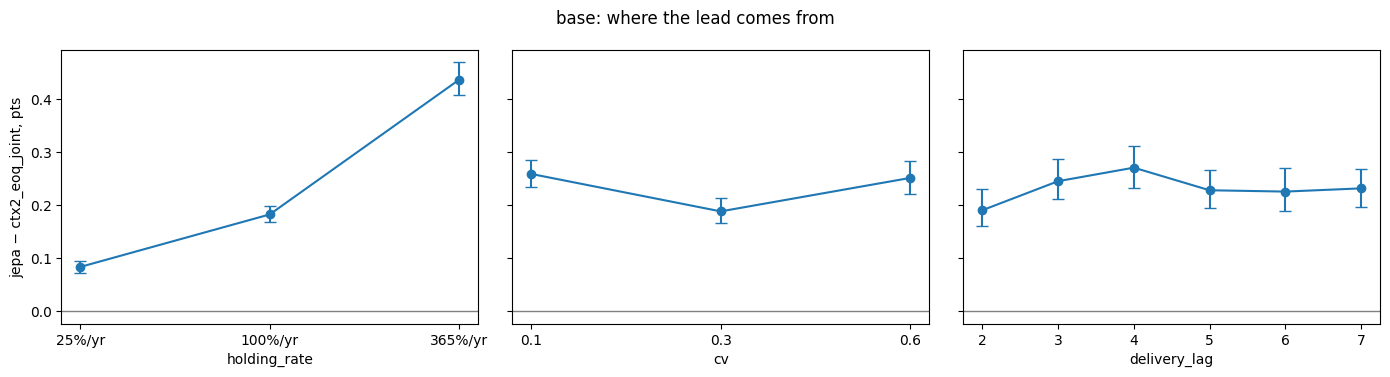

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True)
for ax, key in zip(axes, ("holding_rate", "cv", "delivery_lag")):
    s = strata.loc[key]
    ax.errorbar(s.index, s["diff, pts"], yerr=[s["diff, pts"] - s["95% low"], s["95% high"] - s["diff, pts"]],
                marker="o", capsize=4)
    ax.axhline(0, color="grey", lw=1)
    ax.set_xlabel(key)
axes[0].set_ylabel(f"{ARM} − {ref}, pts")
fig.suptitle(f"{VARIANT}: where the lead comes from")
plt.tight_layout()

## 3 · Re-simulate one world

The stored scores are end-of-year totals. To see the behaviour behind them, this part runs
frozen arms, day by day, on one world. The world is drawn fresh from the **dev** or **tune**
seed block, never the sealed test block. Every arm sees the same demand path.

Textbook arms take a fraction of a second. Planner arms (oracle, JEPA, direct, seasonal ETS)
take a few seconds per episode: about 3 s in `one_product`, 7 s in `base` and 13 s in `no_fee`.

**▶ Try:**
- `SIM_VARIANT`, `SPLIT` (`dev` or `tune`), `WORLD_INDEX`: which world. `WORLD_INDEX` is the
  offset into that split's seed block (dev holds 500, tune 4,096).
- `SIM_ARMS`: two or three arm names. Arms whose model file is not under `DATA_ROOT` are skipped.
- `PRODUCT` and `DAYS`: which product and which window of the 365 days to plot.

In [13]:
SIM_VARIANT = VARIANT
SPLIT = "dev"
WORLD_INDEX = 0
SIM_ARMS = ["planner_oracle", REFERENCE[SIM_VARIANT], "jepa_s0"]
PRODUCT = 0
DAYS = (0, 120)

In [14]:
if SPLIT not in ("dev", "tune"):
    raise ValueError("re-simulate dev or tune worlds only; the sealed test block is never re-run")
seed = protocol.seeds(SPLIT, 1, offset=WORLD_INDEX)[0]
world = sample_world(seed, SPLIT, variant=SIM_VARIANT)


def portable(config: dict) -> dict | None:
    # The frozen config with its model file looked up under DATA_ROOT; None when the file is absent.
    # frozen.json stores absolute paths and is not edited; the sha256 check in make_policy still applies.
    if "model" not in config:
        return config
    path = DATA_ROOT / "models" / Path(config["model"]["path"]).name
    if not path.is_file():
        return None
    return {**config, "model": {**config["model"], "path": str(path)}}


sim_configs = configs_for(SIM_VARIANT)
frames, summaries = [], []
for name in SIM_ARMS:
    config = portable(copy.deepcopy(sim_configs[name]))
    if config is None:
        print(f"skipping {name}: {Path(sim_configs[name]['model']['path']).name} is not under {DATA_ROOT / 'models'}")
        continue
    res = simulate(world, make_policy(config, world))
    frames.append(res.frame)
    summaries.append(res.summary)
ts = pd.concat(frames, ignore_index=True)
ran = list(ts["method"].unique())

print(f"{SPLIT} world {seed} ({SIM_VARIANT}): lag {world.delivery_lag} days, holding rate "
      f"{world.holding_rate * 365:.0%}/yr, cv {world.cv}, order fee {world.order_fee:g}, "
      f"{world.n_products} product(s) with mean demand {', '.join(f'{x:.1f}' for x in world.base_mean)} units/day")
cols = ["score", "lost_units", "fill_rate_demand", "fees", "holding_cost", "order_days", "mean_on_hand"]
pd.DataFrame(summaries).set_index("method")[cols].round(4)

dev world 4000000 (base): lag 6 days, holding rate 100%/yr, cv 0.6, order fee 50, 4 product(s) with mean demand 7.8, 14.8, 12.1, 5.7 units/day


,score,lost_units,fill_rate_demand,fees,holding_cost,order_days,mean_on_hand
method,,,,,,,
planner_oracle,0.9628,16,0.9989,1700.0,3527.1507,34,88.1788
ctx2_eoq_joint,0.9555,40,0.9972,2200.0,3854.5753,44,96.3644
jepa_s0,0.9563,25,0.9983,1900.0,4183.5068,38,104.5877


**How to read the table.** `score` is this one world's margin capture. One world is noisy:
a learned arm can lose to the reference on a single world even though it wins on average.
Part 2's histogram shows how often that happens. `lost_units` are units demanded on days the
shelf was empty, `fees` are order fees paid, and `holding_cost` is the cost of the stock held.

**The daily view** (`analysis.plot_world`), one line per arm:
- **Panel 1:** demand (grey bars), the true mean demand (black) and each arm's sales. Where sales
  fall below demand, the shelf ran empty.
- **Panel 2:** stock on hand (solid) and in transit (dotted).
- **Panel 3:** units ordered, on the day each order was placed.
- **Panel 4:** shop equity.

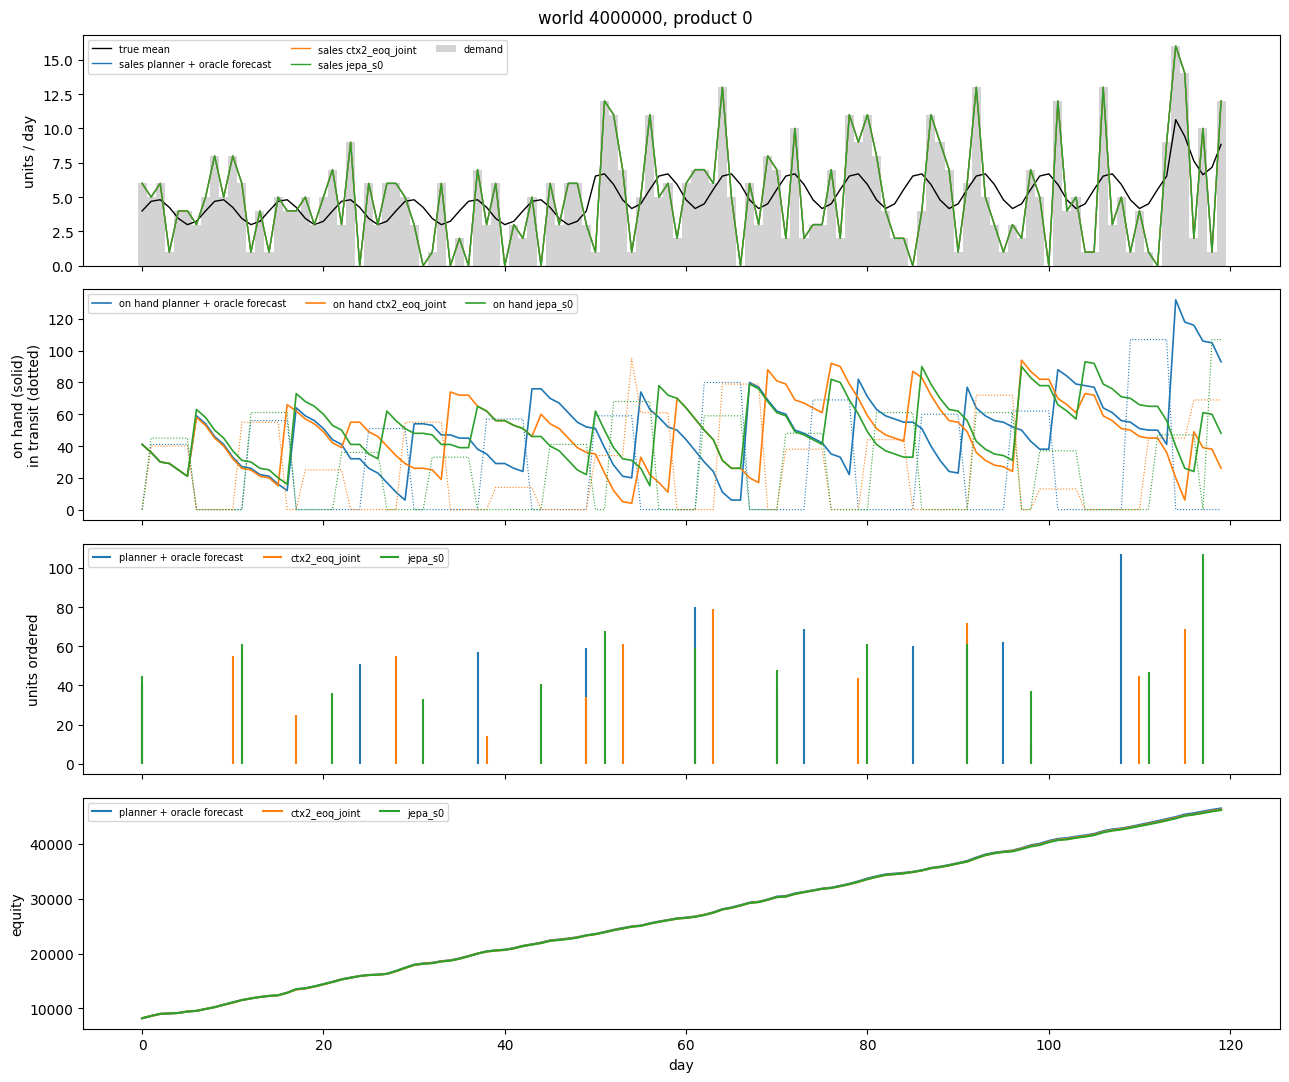

In [15]:
analysis.plot_world(ts, seed, PRODUCT, ran, days=DAYS);

**Lost sales and costs over the whole year.** The three running totals below show what the score
adds up from: units lost to empty shelves, holding cost and order fees, summed over all products.
An arm that keeps more stock loses fewer sales but pays more holding cost. The planner arms trade
the two off using the forecast's quantiles.

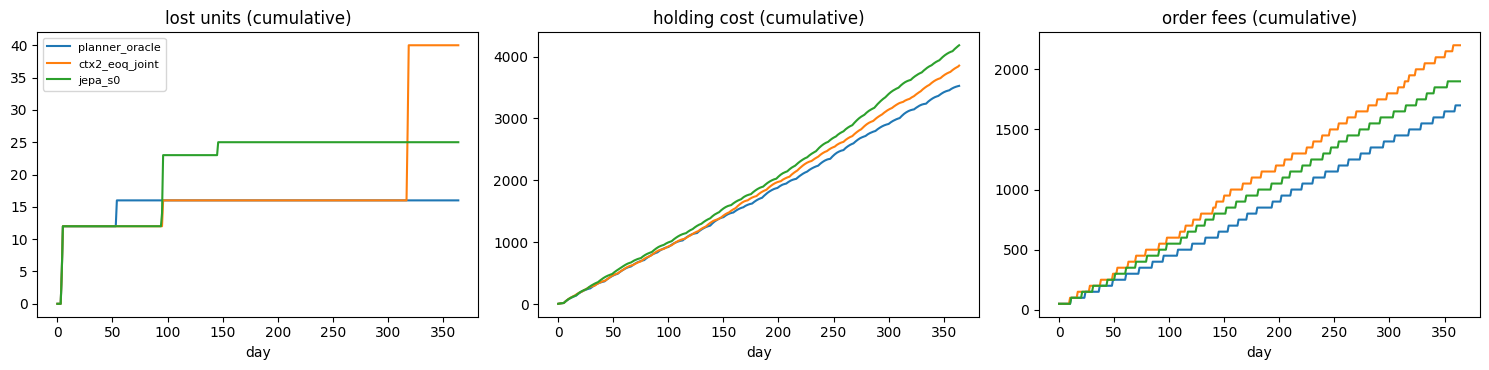

In [16]:
daily = ts.groupby(["method", "day"]).agg(lost=("lost", "sum"), holding=("holding_cost", "first"),
                                           fee=("fee_paid", "first"))
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), sharex=True)
for name in ran:
    g = daily.loc[name].cumsum()
    axes[0].plot(g.index, g["lost"], label=name)
    axes[1].plot(g.index, g["holding"], label=name)
    axes[2].plot(g.index, g["fee"], label=name)
for ax, title in zip(axes, ("lost units (cumulative)", "holding cost (cumulative)", "order fees (cumulative)")):
    ax.set_title(title)
    ax.set_xlabel("day")
axes[0].legend(fontsize=8)
plt.tight_layout()

### What the learned forecaster saw

Planner arms log their forecast every day. The plot below shows the first planner arm in
`SIM_ARMS` that is not the oracle. It compares the planner's median forecast of the next 7 days
of demand with what actually came and with the true mean. Red ticks mark days the product sold
out. On those days the shop saw sales, not demand: it learns from *censored* data.

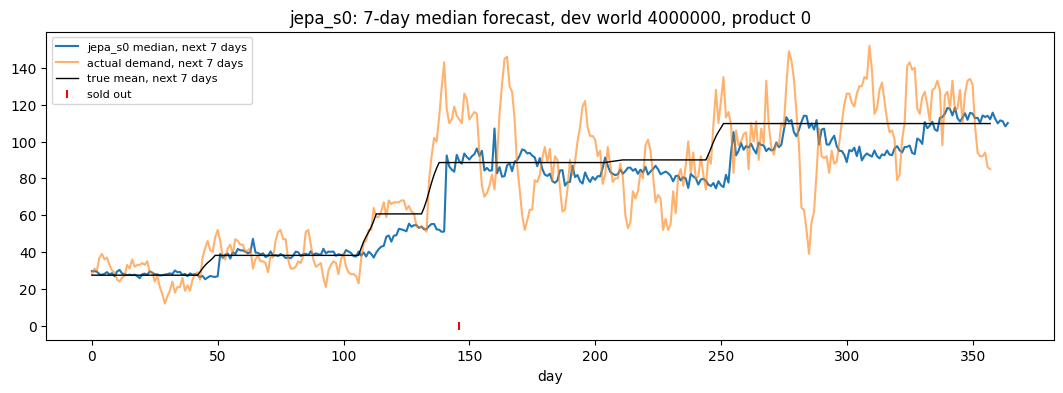

In [17]:
learned = [a for a in ran if sim_configs[a]["kind"] in ("planner", "seasonal_ets") and a != "planner_oracle"]
if learned:
    analysis.plot_forecast(ts, seed, PRODUCT, method=learned[0])
    plt.title(f"{learned[0]}: 7-day median forecast, {SPLIT} world {seed}, product {PRODUCT}")
else:
    print("no learned planner arm in SIM_ARMS")

## Things to try

- Set `VARIANT = "no_fee"`, `ARM = "jepa_s0"` and `REF = "jepa_s0_plain"`. This shows what the T2
  planner knobs add: path coherence `rho`, a higher service cap and separate level paths. Without
  them the same JEPA model *loses* to the reference in `no_fee`.
- Set `ARM = "jepa"` and `REF = "direct"`. The difference is within ±0.02 pts in every variant: the
  JEPA objective adds nothing here.
- Set `ARM = "planner_oracle"`. The oracle's lead over the reference is the controllable
  headroom, 0.34–0.65 pts. JEPA captures roughly a third of it.
- In part 3, move `WORLD_INDEX` until the strata say the lead should be large, then compare
  `SIM_ARMS` on that world. For example, look for a world with a 365%/yr holding rate.
- Swap `jepa_s0` for `seasonal_ets` in `SIM_ARMS` to see a classical forecaster drive the same planner.

The experiment's design, the protocol and the honest limits are in
`experiments/reports/T2-consolidation.md`, `experiments/protocol.yaml` and
`src/perfect_supplier/bench/README.md`.